In [4]:
# =====================================================================
# 1. CORE GRAPH INFRASTRUCTURE 
# =====================================================================

class Vertex:
    def __init__(self, key):
        """Initializes a Vertex with standard and temporal properties."""
        self.id = key
        self.neighbors = {}
        self.color = "white"       # white = unvisited, gray = discovering, black = completed
        self.previous = -1         # Holds the parent vertex object (-1 represents no parent)
        self.discovery_time = 0   # Time step when node is first hit
        self.closing_time = 0     # Time step when node is fully completed

    def set_neighbor(self, nbr, weight=0):
        """Adds a directed connection to a neighbor vertex object."""
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        """Returns neighbor objects sorted alphabetically to match textbook traces."""
        return sorted(self.neighbors.keys(), key=lambda v: str(v.id))

    def get_key(self):
        return self.id

    def __repr__(self):
        return f"Vertex({self.id})"


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)

    def __iter__(self):
        """Allows loops directly over all internal Vertex objects."""
        return iter(self.vertices.values())


# =====================================================================
# 2. TARGET CLASS IMPLEMENTATION (Your Exact Textbook Syntax)
# =====================================================================

class DFSGraph(Graph):
    def __init__(self):
        super().__init__()
        self.time = 0  # Global step counter tracking discovery/closing sequences

    def dfs(self):
        # 1. Sanitization Phase: Reset all vertex states across the graph completely
        for vertex in self:
            vertex.color = "white"
            vertex.previous = -1
            
        # 2. Forest Assembly Phase: Iterate over everything to ensure no isolated nodes are missed
        for vertex in self:
            if vertex.color == "white":
                self.dfs_visit(vertex)

    def dfs_visit(self, start_vertex):
        # Mark as gray to show exploration has officially begun
        start_vertex.color = "gray"
        self.time = self.time + 1
        start_vertex.discovery_time = self.time
        print(f"▶️  Discovered [{start_vertex.get_key()}] at Time Step: {start_vertex.discovery_time}")
        
        # Plunge recursively down neighbors as deeply as possible
        for next_vertex in start_vertex.get_neighbors():
            if next_vertex.color == "white":
                next_vertex.previous = start_vertex
                self.dfs_visit(next_vertex)  # Recursive stack invocation jump
                
        # All nested pathways are exhausted; mark as black (finalized)
        start_vertex.color = "black"
        self.time = self.time + 1
        start_vertex.closing_time = self.time
        print(f"🛑 Finalized  [{start_vertex.get_key()}] at Time Step: {start_vertex.closing_time}")


# =====================================================================
# 3. VERIFICATION SYSTEM DRIVER BLOCK
# =====================================================================

# Rebuild the 6-node graphic layout matching your sample figures
dfs_graph = DFSGraph()
dfs_graph.add_edge("A", "B")
dfs_graph.add_edge("A", "D")
dfs_graph.add_edge("B", "C")
dfs_graph.add_edge("B", "D")
dfs_graph.add_edge("D", "E")
dfs_graph.add_edge("E", "B")
dfs_graph.add_edge("E", "F")
dfs_graph.add_edge("F", "C")

print("=====================================================================")
print("🚀 RUNNING SPECIFIED DFS GRAPH PROCESSOR")
print("=====================================================================\n")

# Run algorithm execution trace
dfs_graph.dfs()

print("\n" + "=" * 70)
print("🏁 RESULTING TEMPORAL MATRIX OUTPUT METRICS")
print("=" * 70)
print(f"{'Vertex':<8} | {'Discovery Time':<15} | {'Closing Time':<12} | {'Predecessor':<12}")
print("-" * 70)

for key in sorted(dfs_graph.vertices.keys()):
    v = dfs_graph.get_vertex(key)
    pred_val = v.previous.get_key() if v.previous != -1 else "None (Root)"
    print(f"{v.get_key():<8} | {v.discovery_time:<15} | {v.closing_time:<12} | {pred_val:<12}")
print("-" * 70)


🚀 RUNNING SPECIFIED DFS GRAPH PROCESSOR

▶️  Discovered [A] at Time Step: 1
▶️  Discovered [B] at Time Step: 2
▶️  Discovered [C] at Time Step: 3
🛑 Finalized  [C] at Time Step: 4
▶️  Discovered [D] at Time Step: 5
▶️  Discovered [E] at Time Step: 6
▶️  Discovered [F] at Time Step: 7
🛑 Finalized  [F] at Time Step: 8
🛑 Finalized  [E] at Time Step: 9
🛑 Finalized  [D] at Time Step: 10
🛑 Finalized  [B] at Time Step: 11
🛑 Finalized  [A] at Time Step: 12

🏁 RESULTING TEMPORAL MATRIX OUTPUT METRICS
Vertex   | Discovery Time  | Closing Time | Predecessor 
----------------------------------------------------------------------
A        | 1               | 12           | None (Root) 
B        | 2               | 11           | A           
C        | 3               | 4            | B           
D        | 5               | 10           | B           
E        | 6               | 9            | D           
F        | 7               | 8            | E           
----------------------------------

**Topological Sorting**

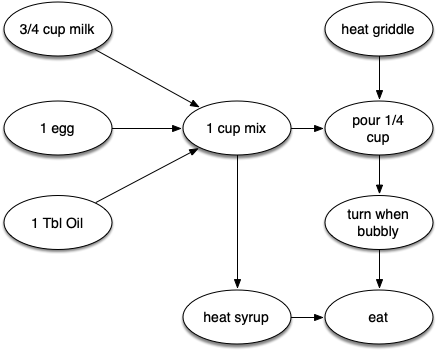

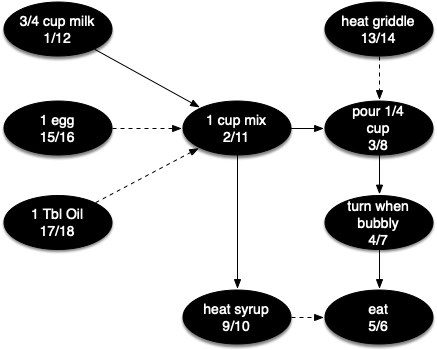

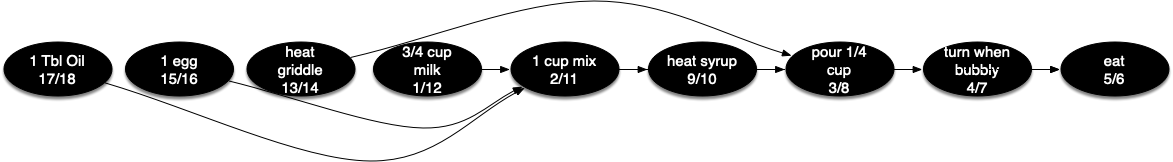

In [6]:
# =====================================================================
# 1. CORE GRAPH INFRASTRUCTURE WITH TEMPORAL DATA STRUC
# =====================================================================

class Vertex:
    def __init__(self, key):
        """Initializes a Vertex for a recipe step."""
        self.id = key
        self.neighbors = {}
        self.color = "white"       # white = unvisited, gray = discovering, black = completed
        self.previous = -1         # Predecessor mapping placeholder (-1 = no parent)
        self.discovery_time = 0   
        self.closing_time = 0     

    def set_neighbor(self, nbr, weight=0):
        """Adds a directed connection indicating a task dependency (self -> nbr)."""
        self.neighbors[nbr] = weight

    def get_neighbors(self):
        """Returns neighbor objects sorted alphabetically to guarantee runtime stability."""
        return sorted(self.neighbors.keys(), key=lambda v: str(v.id))

    def get_key(self):
        return self.id

    def __repr__(self):
        return f"Vertex({self.id})"


class Graph:
    def __init__(self):
        self.vertices = {}

    def set_vertex(self, key):
        if key not in self.vertices:
            self.vertices[key] = Vertex(key)
        return self.vertices[key]

    def get_vertex(self, key):
        return self.vertices.get(key, None)

    def add_edge(self, from_key, to_key, weight=0):
        """Creates a dependency link where from_key must happen BEFORE to_key."""
        if from_key not in self.vertices:
            self.set_vertex(from_key)
        if to_key not in self.vertices:
            self.set_vertex(to_key)
        self.vertices[from_key].set_neighbor(self.vertices[to_key], weight)

    def __iter__(self):
        return iter(self.vertices.values())


# =====================================================================
# 2. EXTENDED DFS & TOPOLOGICAL SORT ENGINE CLASS
# =====================================================================

class DFSGraph(Graph):
    def __init__(self):
        super().__init__()
        self.time = 0  # Global tracker tracking exploration progress steps

    def dfs(self):
        """Computes structural discovery and closing times for all task nodes."""
        for vertex in self:
            vertex.color = "white"
            vertex.previous = -1
        for vertex in self:
            if vertex.color == "white":
                self.dfs_visit(vertex)

    def dfs_visit(self, start_vertex):
        start_vertex.color = "gray"
        self.time = self.time + 1
        start_vertex.discovery_time = self.time
        
        for next_vertex in start_vertex.get_neighbors():
            if next_vertex.color == "white":
                next_vertex.previous = start_vertex
                self.dfs_visit(next_vertex)
                
        start_vertex.color = "black"
        self.time = self.time + 1
        start_vertex.closing_time = self.time

    def topological_sort(self):
        """
        Executes a Topological Sort on the Directed Acyclic Graph (DAG).
        Returns a linearly ordered list of keys sorted by decreasing closing time.
        """
        # Step 1: Run DFS to compute the closing times
        self.dfs()
        
        # Step 2: Extract all Vertex objects from the graph map structure
        all_vertices = list(self.vertices.values())
        
        # Step 3: Sort the vertices in decreasing order of closing time (reverse=True)
        all_vertices.sort(key=lambda vertex: vertex.closing_time, reverse=True)
        
        # Step 4: Extract and return the clean ordered list of string task names
        return [vertex.get_key() for vertex in all_vertices]


# =====================================================================
# 3. VERIFICATION SYSTEM DRIVER (Pancake Recipe Graph)
# =====================================================================

# Build the pancake step dependency graph described in the text
pancake_graph = DFSGraph()

# Add structural dependencies: add_edge(task_A, task_B) means A must happen BEFORE B
pancake_graph.add_edge("1 Egg", "Mix Ingredients")
pancake_graph.add_edge("1 Cup Mix", "Mix Ingredients")
pancake_graph.add_edge("1 Tbsp Oil", "Mix Ingredients")
pancake_graph.add_edge("3/4 Cup Milk", "Mix Ingredients")

pancake_graph.add_edge("Mix Ingredients", "Spoon onto Griddle")
pancake_graph.add_edge("Heat Griddle", "Spoon onto Griddle")

pancake_graph.add_edge("Spoon onto Griddle", "Turn when Bubble")
pancake_graph.add_edge("Turn when Bubble", "Eat Pancakes")
pancake_graph.add_edge("Heat Syrup", "Eat Pancakes")

print("=====================================================================")
print("🥞 RUNNING RECIPE SCHEDULER: TOPOLOGICAL SORT ENGINE TRACE")
print("=====================================================================\n")

# Compute the final sequential execution workflow path array
ordered_recipe_steps = pancake_graph.topological_sort()

print("\n" + "=" * 75)
print("📊 COMPLETE PROCESS TIMELINE DATA MATRIX")
print("=" * 75)
print(f"{'Recipe Task Step':<22} | {'Discovery Time':<15} | {'Closing Time':<12}")
print("-" * 75)
for key in sorted(pancake_graph.vertices.keys()):
    v = pancake_graph.get_vertex(key)
    print(f"{v.get_key():<22} | {v.discovery_time:<15} | {v.closing_time:<12}")
print("-" * 75)

print("\n" + "=" * 75)
print("🏁 FINAL AMBIGUITY-FREE STEP SEQUENCE WORKFLOW")
print("=" * 75)
for step_num, task in enumerate(ordered_recipe_steps, 1):
    print(f" Step {step_num:02d}: {task}")
print("=" * 75)


🥞 RUNNING RECIPE SCHEDULER: TOPOLOGICAL SORT ENGINE TRACE


📊 COMPLETE PROCESS TIMELINE DATA MATRIX
Recipe Task Step       | Discovery Time  | Closing Time
---------------------------------------------------------------------------
1 Cup Mix              | 11              | 12          
1 Egg                  | 1               | 10          
1 Tbsp Oil             | 13              | 14          
3/4 Cup Milk           | 15              | 16          
Eat Pancakes           | 5               | 6           
Heat Griddle           | 17              | 18          
Heat Syrup             | 19              | 20          
Mix Ingredients        | 2               | 9           
Spoon onto Griddle     | 3               | 8           
Turn when Bubble       | 4               | 7           
---------------------------------------------------------------------------

🏁 FINAL AMBIGUITY-FREE STEP SEQUENCE WORKFLOW
 Step 01: Heat Syrup
 Step 02: Heat Griddle
 Step 03: 3/4 Cup Milk
 Step 04: 1 Tbsp O

#### playground